# KT20 Scan Demo

This notebook demonstrates a practical workflow for loading KT20 magnetic susceptibility scan exports with the `scandrivers` package and exploring the resulting data.


In [8]:
# Install the package if needed
# %pip install -e ..

from pathlib import Path

from scandrivers import load_data

project_root = Path.cwd().resolve()
if not (project_root / "pyproject.toml").exists():
    project_root = project_root.parent

scan_path = project_root / "data" / "kt20" / "kt20_0467" / "289" / "record_scanner_10khz_289.csv"
print(f"Project root: {project_root}")
print(f"Scan path: {scan_path}")


Project root: /mnt/DCDCDB23DCDAF72C/wcarleton/Projects/MagSus
Scan path: /mnt/DCDCDB23DCDAF72C/wcarleton/Projects/MagSus/data/kt20/kt20_0467/289/record_scanner_10khz_289.csv


## Load scan files from the notebooks workflow

This section locates and loads a scan CSV using the package loader.

In [9]:
df = load_data(scan_path, driver="kt20")
df.head()

,record_id,date,time,frequency,pin,diameter_correction,measurement_index,susceptibility_10_3si,trigger_data
0,289,14.03.2026,14:25:38,10kHz,No,None,1,0.1939,0
1,289,14.03.2026,14:25:38,10kHz,No,None,2,0.1127,0
2,289,14.03.2026,14:25:38,10kHz,No,None,3,0.0000,0
3,289,14.03.2026,14:25:38,10kHz,No,None,4,1.1013,0
4,289,14.03.2026,14:25:38,10kHz,No,None,5,0.5028,0


## Inspect loaded scans

Inspect the metadata columns and basic properties of the loaded scan data.

In [10]:
df.columns.tolist()
df.shape

df[["record_id", "date", "time", "frequency", "susceptibility_10_3si"]].head()

,record_id,date,time,frequency,susceptibility_10_3si
0,289,14.03.2026,14:25:38,10kHz,0.1939
1,289,14.03.2026,14:25:38,10kHz,0.1127
2,289,14.03.2026,14:25:38,10kHz,0.0000
3,289,14.03.2026,14:25:38,10kHz,1.1013
4,289,14.03.2026,14:25:38,10kHz,0.5028


## Run package workflows on scans

This section shows a simple real-world analysis step using the loaded scan values.

In [11]:
summary = df["susceptibility_10_3si"].describe()
summary

count    19.000000
mean      0.278284
std       0.383340
min       0.000000
25%       0.000000
50%       0.000000
75%       0.510800
max       1.164200
Name: susceptibility_10_3si, dtype: float64

## Visualize scan data

Plot the susceptibility series to inspect the scan visually.

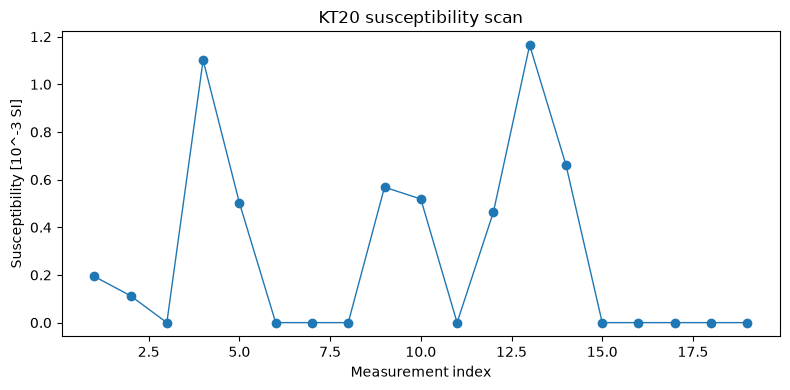

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(df["measurement_index"], df["susceptibility_10_3si"], marker="o", linestyle="-", linewidth=1)
plt.xlabel("Measurement index")
plt.ylabel("Susceptibility [10^-3 SI]")
plt.title("KT20 susceptibility scan")
plt.tight_layout()
plt.show()

## Save or export results

Export the processed DataFrame to a CSV file for later use.

In [13]:
output_path = project_root / "notebooks" / "loaded_scan_demo.csv"
df.to_csv(output_path, index=False)
print(f"Saved processed scan data to {output_path}")

Saved processed scan data to /mnt/DCDCDB23DCDAF72C/wcarleton/Projects/MagSus/notebooks/loaded_scan_demo.csv


## Load many scans into one DataFrame

This section loops over all KT20 scan subfolders under the sample data directory and combines them into a single DataFrame.

In [14]:
from pathlib import Path

import pandas as pd

scan_root = project_root / "data" / "kt20" / "kt20_0467"
scan_dirs = sorted([p for p in scan_root.iterdir() if p.is_dir() and p.name.isdigit()])

frames = []
for scan_dir in scan_dirs:
    frames.append(load_data(scan_dir, driver="kt20", scan_mode="scan"))

combined_df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
combined_df.head()

,record_id,date,time,frequency,pin,diameter_correction,measurement_index,susceptibility_10_3si,trigger_data
0,117,14.03.2026,11:55:40,10kHz,No,None,1,0.0,0
1,117,14.03.2026,11:55:40,10kHz,No,None,2,0.0,0
2,117,14.03.2026,11:55:40,10kHz,No,None,3,0.0,0
3,117,14.03.2026,11:55:40,10kHz,No,None,4,0.0,0
4,117,14.03.2026,11:55:40,10kHz,No,None,5,0.0,0


In [16]:
combined_df.shape

(3043, 9)